In [1]:
include("../src/load_all.jl")

Loaded successfully.


In [2]:
case_FVM = SodCase.make_case(nx=200, ny=2, degree=0, final_time=0.2)
solution_FVM = Solver.raw_solve_2d(case_FVM; time_method=:SSPRK3, verbose=true, save_every=20, dt_max=case_FVM.final_time/20)
(solution_FVM.time, solution_FVM.number_of_steps, solution_FVM.number_of_retries)

step=1 time=0.001267731382092762 dt=0.001267731382092762 retries=0
step=2 time=0.0022054853326790823 dt=0.0009377539505863205 retries=0
step=3 time=0.002971472047030967 dt=0.0007659867143518846 retries=0
step=4 time=0.0036355819921138066 dt=0.0006641099450828399 retries=0
step=5 time=0.004232501680739055 dt=0.0005969196886252483 retries=0
step=6 time=0.00478213054170615 dt=0.000549628860967095 retries=0
step=7 time=0.005296997148678442 dt=0.0005148666069722917 retries=0
step=8 time=0.005785519333606952 dt=0.0004885221849285102 retries=0
step=9 time=0.0062536297468697224 dt=0.0004681104132627701 retries=0
step=10 time=0.0067056639905554195 dt=0.000452034243685697 retries=0
step=11 time=0.007144880944909 dt=0.00043921695435358046 retries=0
step=12 time=0.007573784964083341 dt=0.0004289040191743409 retries=0
step=13 time=0.007994334614020495 dt=0.0004205496499371531 retries=0
step=14 time=0.008408083118354615 dt=0.00041374850433411985 retries=0
step=15 time=0.00881627595565275 dt=0.000408

(0.2, 597, 0)

In [ ]:
Diagnostics.conservation_report(solution_FVM)

(initial_total_ls = [0.05624999999999967, 0.0, 0.0, 0.1324999999999991], final_total_ls = [0.05624999999999967, 0.017999999999998375, 6.318555846687795e-19, 0.13249999999999665], change_ls = [0.0, 0.017999999999998375, 6.318555846687795e-19, -2.4424906541753444e-15], boundary_change_ls = [0.0, 0.017999999999998694, 6.318555846687836e-19, -6.183779992094439e-16], balance_error_ls = [0.0, -3.191891195797325e-16, -4.140749380432557e-33, -1.8241126549659006e-15])

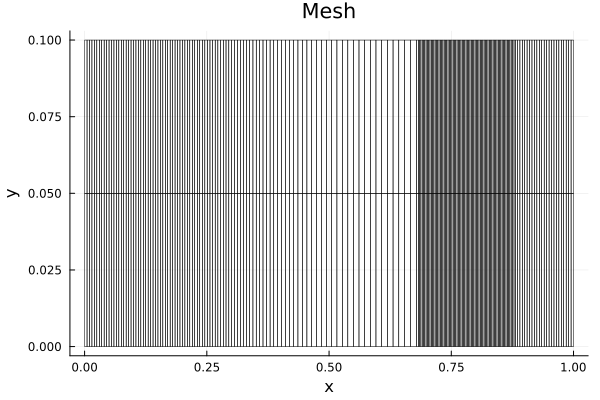

In [ ]:
display(Visualization.plot_mesh(solution_FVM.state,case_FVM.mesh))

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\sod_density.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\sod_density.gif")
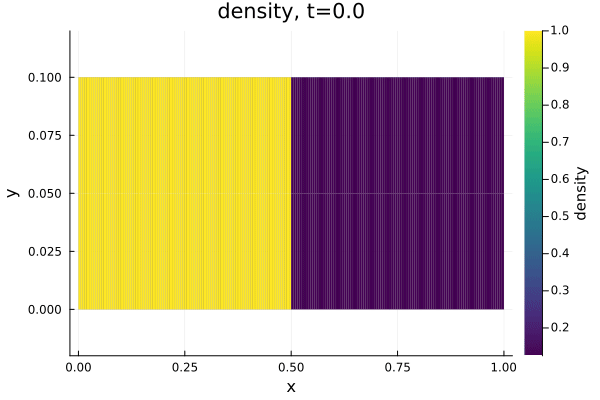

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\sod_pressure.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\sod_pressure.gif")
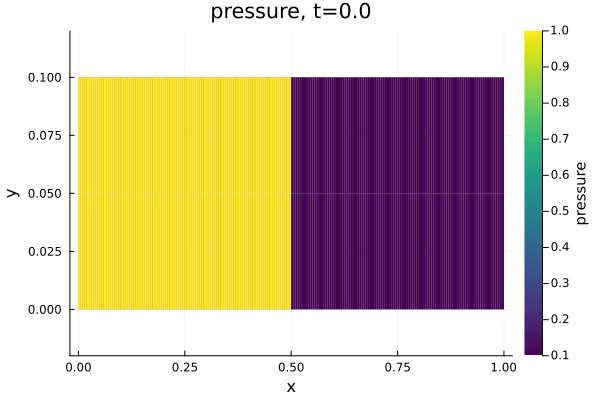

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\sod_velocity_x.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\sod_velocity_x.gif")
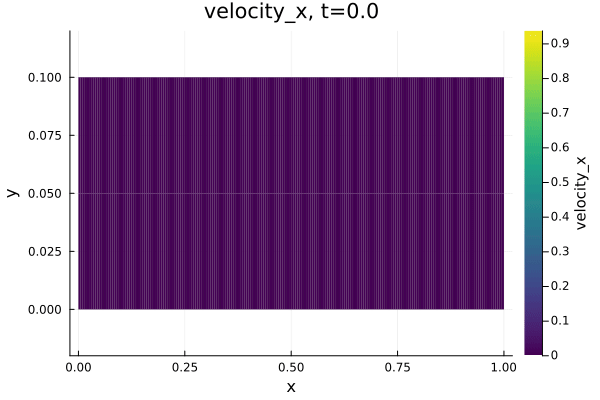

[ Info: Saved animation to c:\Users\Peikai_Li\Desktop\lagrangian_ofdg_2d_simple_release\results\sod_velocity_y.gif


Plots.AnimatedGif("c:\\Users\\Peikai_Li\\Desktop\\lagrangian_ofdg_2d_simple_release\\results\\sod_velocity_y.gif")
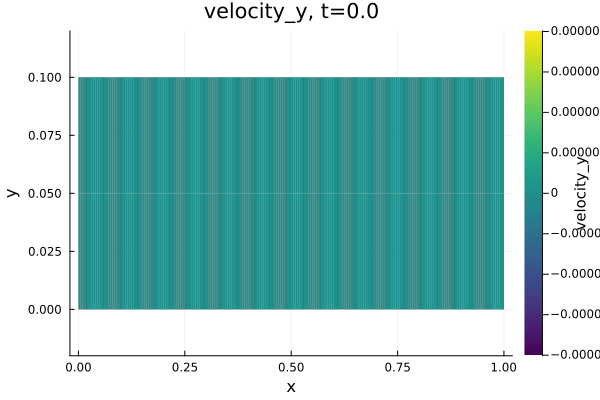

In [7]:
for field in (:density, :pressure, :velocity_x, :velocity_y)
    gif_result = Visualization.draw_gif(
        solution_FVM,
        "../results/$(string(case_FVM.problem.name))FVM_$(field).gif";
        field = field,
        fps = 5,
    )
    display(gif_result)
end
# plot this is very very slow!!!!!!!!!!!

## Try to directly non OF in higher order for fun

In [9]:
case_test = SodCase.make_case(; nx=50, ny=2, degree=2, final_time=0.2,
                   OF=false, characteristic=false, positivity=false, cfl=0.3)
solution_test = Solver.raw_solve_2d(case_test; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case_test.final_time/20)

step=1 time=0.0006338656910463863 dt=0.0006338656910463863 retries=3
step=2 time=0.0012431358644618283 dt=0.0006092701734154419 retries=3
step=3 time=0.0018053258980371292 dt=0.0005621900335753009 retries=3
step=4 time=0.002325326534369949 dt=0.0005200006363328196 retries=3
step=5 time=0.0032926319964616357 dt=0.0009673054620916868 retries=2
step=6 time=0.004978955706630973 dt=0.0016863237101693367 retries=1
step=7 time=0.005614993324952049 dt=0.0006360376183210763 retries=2
step=8 time=0.00589422215019291 dt=0.0002792288252408611 retries=3
step=9 time=0.006418898441587823 dt=0.0005246762913949121 retries=2
step=10 time=0.006650757221533091 dt=0.00023185877994526762 retries=3
step=11 time=0.006678184595050262 dt=2.7427373517171233e-5 retries=6
step=12 time=0.0067054350129109935 dt=2.725041786073136e-5 retries=6


LoadError: DomainError with 25:
nonphysical polynomial value at point=(0.5062021414566941, 0.0): rho=0.2072346810796582, p=-1.1152496906996488e-5

## Normal test for higher order

In [13]:
case_P2 = SodCase.make_case(; nx=200, ny=2, degree=2, final_time=0.2,
                   OF=true, characteristic=false, positivity=false, cfl=0.3)
solution_P2 = Solver.raw_solve_2d(case_P2; time_method=:SSPRK3, verbose=true, save_every=10, dt_max=case_P2.final_time/20)
solution_P2.time, solution_P2.number_of_steps, solution_P2.number_of_retries

step=1 time=0.001267731382092762 dt=0.001267731382092762 retries=0
step=2 time=0.002063881089485014 dt=0.000796149707392252 retries=0
step=3 time=0.002663516151205454 dt=0.0005996350617204397 retries=0
step=4 time=0.003154260865864158 dt=0.0004907447146587041 retries=0
step=5 time=0.0035804316200382814 dt=0.00042617075417412335 retries=0
step=6 time=0.003968323752961912 dt=0.00038789213292363047 retries=0


LoadError: AssertionError: The constant basis must have zero mean time derivative.